# 5. Calcit → Dolomit mit Advektion

**Ziel.** Strömung hinzufügen. Eine MgCl₂-Lösung wird in eine 0,5 m lange Calcitsäule gepumpt. Calcit löst sich, das freigesetzte Carbonat trifft auf Mg, und
**Dolomit** fällt in einem Band aus, das die Säule hinabwandert und sich dahinter wieder auflöst. Mit diesem Benchmark werden Codes für reaktiven Transport verglichen
([doi:10.1007/s10596-019-09919-3](https://doi.org/10.1007/s10596-019-09919-3), Abschnitt 4.4, Abb. 6).

Neu in `case.yaml`:

- **`transport.material.darcy_flux`**: Advektion in $+x$-Richtung;
- **ein `outflow`-Rand** rechts, an dem Wasser mit der Zusammensetzung der letzten Zelle austritt;
- **ein feines Gitter**, weil das Upwind-Verfahren Fronten verschmiert;
- **ein GEMS-Projekt, dessen unabhängige Komponenten nicht alle Elemente sind** (kein `O`);
- ein Rezept, das durch Skalieren eines GEMS-Zustands auf φ = 0,32 entsteht ([wie](../yaml/from_gems.md)).

| | |
|---|---|
| Modus | `coupled` |
| Fallordner | `FEniCSx_GEMS/example/demo_calcite_dolomite` (dieses Notebook läuft dort) |
| Gebiet | 0,5 m, 1000 Zellen, 105 Schritte zu 200 s |
| Laufzeit | etwa 25 s |

In [1]:
print(open('case.yaml').read())

# Bench5 / Benchmark 4: MgCl2 injection into a calcite column (paper s10596-019-09919-3, 4.4, Fig. 6),
# reproduced with the four modules two folders up (FEniCSx_GEMS_Beginner).
# Run from this folder:  python ../../coupling.py case.yaml   (or Run.cmd, or the notebook)
#
# 0.5 m column, porosity 0.32, pore velocity 9.375e-6 m/s, D = 2.01e-8 m2/s,
# MgCl2 (Mg 1, Cl 2 mol/m3 water) enters on the left, advective outflow on the right,
# calcite dissolves, dolomite forms in a moving band. dt = 200 s, end = 21000 s.

# 1. chemistry.py: GEMS project, chemical conditions, and recipes.
chemistry:
  project: chemistry_data/ic-independent-dat.lst   # C-Ca-Cl-H-Mg-Zz basis, calcite lower limit removed
  temperature: 298.15                  # K
  pressure: 100000                     # Pa
  aqueous_phase: aq_gen
  solid_phases: [Calcite, Dolomite-dis]

  # No Gibbs energy adjustments in this benchmark.
  gibbs: {}

  # Sample: element amounts in mol per 1 dm3 of BULK sample (pore water + solids).
  

### Strömung in `case.yaml`

Der Benchmark gibt eine Porengeschwindigkeit $v = 9{,}375\times10^{-6}$ m/s und einen Dispersionskoeffizienten $D = 2{,}01\times10^{-8}$ m²/s vor. In der Flussform des Codes werden
beide mit φ multipliziert:

$$
q = \phi v = 0{,}32 \times 9{,}375\times10^{-6} = 3{,}0\times10^{-6}\ \text{m/s},\qquad D_e = \phi D = 6{,}432\times10^{-9}\ \text{m}^2/\text{s}
$$

```yaml
transport:
  material: {phi: 0.32, De: 6.432e-09, darcy_flux: 3.0e-06}
  boundary:
    left:  {type: dirichlet}   # Zustrom von chemistry.inlet
    right: {type: outflow}     # Wasser tritt aus; diffusiver Gradient null
```

Mit Strömung muss der linke Rand `dirichlet` und der rechte `outflow` oder `dirichlet` sein; jede andere Kombination bricht beim Start ab. Die Courant-Zahl ist
$q\,\Delta t/(\phi h) = 9{,}375\times10^{-6}\cdot 200 / 5\times10^{-4} = 3{,}75$; das implizite Euler-Verfahren ist dort stabil.

### Das chemische System hat kein O

Das Projekt listet die unabhängigen Komponenten `C, Ca, Cl, H, Mg, Zz`. Wasser wird allein aus `H` gebildet, und der O-Gehalt jeder Spezies folgt aus den übrigen; eine
zusätzliche O-Zeile machte die Stöchiometriematrix singulär. Das Rezept enthält daher kein `O`: Verwenden Sie die Namen, die das Projekt auflistet, welche es auch sind.
Das Zustromwasser hält C und Ca bei 1e-9 mol, damit GEMS immer etwas von jeder Komponente hat.

## Rechnen

In [2]:
!python ../../coupling.py case.yaml 2>&1 | grep -v gems3k | tail -n 2

step=105, time=21000 s, balance=5.166e-09 mol/m2, chemistry=2.963e-09 mol/m3, water mismatch=0.00%
Saved: FEniCSx_GEMS/example/demo_calcite_dolomite/results


## Vergleich mit der Veröffentlichung (t = 21 000 s)

Links: dieses Modell im Layout von Abb. 6. Rechts: die veröffentlichte Abbildung. Minerale sind wie in der Veröffentlichung von mol/m³ Gesamtvolumen in mol pro m³ Wasser (÷ φ) umgerechnet.

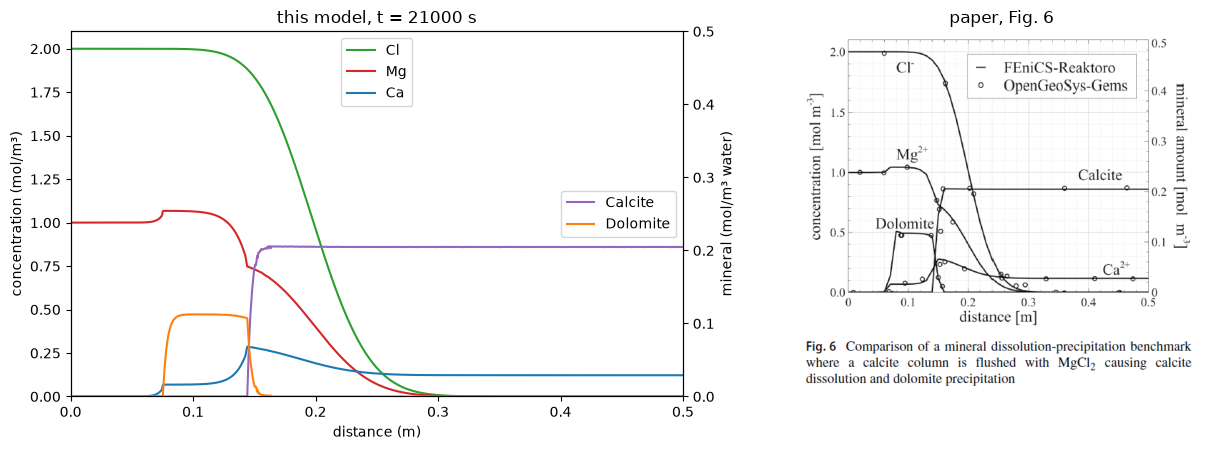

calcite plateau 0.2057 mol/m3 water
dolomite peak   0.1125 mol/m3 water, band 0.076-0.152 m


In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
phi = 0.32
p = pd.read_csv('results/profiles.csv')
s = p[p.time_s == p.time_s.max()].sort_values('x_m')

fig, (ax1, axi) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1.1, 1]})
ax2 = ax1.twinx()
ax1.plot(s.x_m, s.Cl_c_mol_m3_water, color='tab:green', label='Cl')
ax1.plot(s.x_m, s.Mg_c_mol_m3_water, color='tab:red', label='Mg')
ax1.plot(s.x_m, s.Ca_c_mol_m3_water, color='tab:blue', label='Ca')
ax2.plot(s.x_m, s.Calcite_mol_m3_bulk / phi, color='tab:purple', label='Calcite')
ax2.plot(s.x_m, s['Dolomite-dis_mol_m3_bulk'] / phi, color='tab:orange', label='Dolomite')
ax1.set(xlim=(0, 0.5), ylim=(0, 2.1), xlabel='distance (m)', ylabel='concentration (mol/m³)')
ax2.set(ylim=(0, 0.5), ylabel='mineral (mol/m³ water)')
ax1.legend(loc='upper center'); ax2.legend(loc='center right')
ax1.set_title(f'this model, t = {s.time_s.iloc[0]:.0f} s')
axi.imshow(plt.imread('reference/paper_fig6_bench5.png')); axi.axis('off'); axi.set_title('paper, Fig. 6')
plt.tight_layout(); plt.show()

dol = (s['Dolomite-dis_mol_m3_bulk'] / phi).to_numpy(); band = s.x_m.to_numpy()[dol > 0.01]
print(f'calcite plateau {(s.Calcite_mol_m3_bulk / phi).max():.4f} mol/m3 water')
print(f'dolomite peak   {dol.max():.4f} mol/m3 water, band {band.min():.3f}-{band.max():.3f} m')

Die Lage der Mg- und Cl-Fronten, der Calcit-Lösungsfront und des Dolomitbands stimmt mit der veröffentlichten Abbildung überein.

## Wie das Band wandert

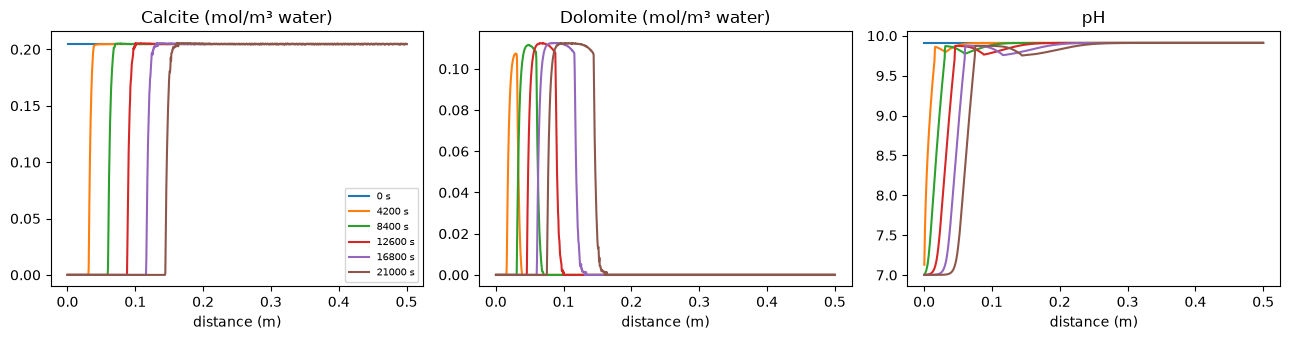

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for k, (t, g) in enumerate(p.groupby('time_s')):
    g = g.sort_values('x_m')
    axes[0].plot(g.x_m, g.Calcite_mol_m3_bulk / phi, color=f'C{k}', label=f'{t:.0f} s')
    axes[1].plot(g.x_m, g['Dolomite-dis_mol_m3_bulk'] / phi, color=f'C{k}')
    axes[2].plot(g.x_m, g.pH, color=f'C{k}')
for ax, title in zip(axes, ['Calcite (mol/m³ water)', 'Dolomite (mol/m³ water)', 'pH']):
    ax.set(title=title, xlabel='distance (m)')
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

Dolomit bildet sich dort, wo Mg auf sich lösenden Calcit trifft. Hinter dem Band ist das zuströmende MgCl₂-Wasser an Dolomit untersättigt, der sich wieder löst. So wandert das
Band mit der Calcitfront.

## Warum 1000 Zellen? Numerische Dispersion

Das Upwind-Verfahren fügt zum physikalischen $D_e$ eine numerische Dispersion von etwa $q h/2$ hinzu. Mit 1000 Zellen ($h$ = 0,5 mm) sind das
$0{,}75\times10^{-9}$ m²/s, etwa 12 % von $D_e$; mit 100 Zellen wären es das 1,2-Fache von $D_e$. Eine geänderte Zeile zeigt den Effekt:

Saved: FEniCSx_GEMS/example/demo_calcite_dolomite/results_100cells


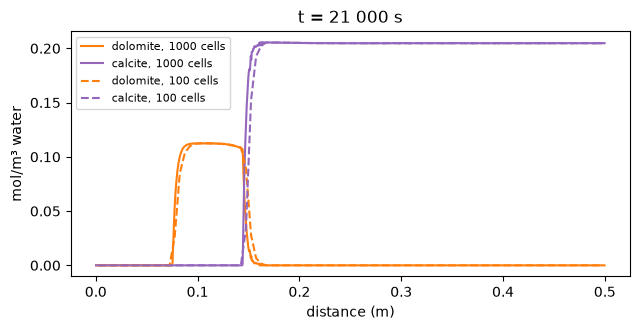

In [5]:
import yaml
case = yaml.safe_load(open('case.yaml'))
case['transport']['geometry']['cells'] = 100
case['output']['folder'] = 'results_100cells'
yaml.safe_dump(case, open('case_100cells.yaml', 'w'), sort_keys=False)
!python ../../coupling.py case_100cells.yaml 2>&1 | grep -v gems3k | tail -n 1

c = pd.read_csv('results_100cells/profiles.csv'); c = c[c.time_s == c.time_s.max()].sort_values('x_m')
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for d, lab, st in ((s, '1000 cells', '-'), (c, '100 cells', '--')):
    ax.plot(d.x_m, d['Dolomite-dis_mol_m3_bulk'] / phi, st, color='tab:orange', label=f'dolomite, {lab}')
    ax.plot(d.x_m, d.Calcite_mol_m3_bulk / phi, st, color='tab:purple', label=f'calcite, {lab}')
ax.set(xlabel='distance (m)', ylabel='mol/m³ water', title='t = 21 000 s'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Mit 100 Zellen liegt das Band an derselben Stelle; nur seine Ränder verteilen sich über einige grobe Zellen. Gleichgewichtschemie hält die Mineralfronten scharf, deshalb spielt das
Gitter hier eine kleinere Rolle, als die Dispersionsabschätzung vermuten lässt. Bei anderen Problemen kann es viel ausmachen: verfeinern, bis sich das Ergebnis nicht mehr ändert.

Sie kennen jetzt jeden Abschnitt von `case.yaml`. Die [Referenzseiten](../yaml/index.md) nennen die übrigen Optionen, etwa `start: warm` und `on_failure: skip`
für schwierige Chemie.